Test test test 


In [1]:
%load_ext autoreload
%autoreload 2

# standard imports
import os
import numpy as np
from sklearn.linear_model import Ridge
import torch
import re
from sklearn.model_selection import StratifiedKFold
import scipy
from tqdm.notebook import tqdm
import pandas as pd
import warnings
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt

# custom imports

from compcats.models import resnet50_faceobfuscation
from compcats.datasets.fmri import murty185
from compcats.utils import model_utils, misc_utils, responsecomparison_utils
from compcats.encoder import encode

MODELS_DIR = 'models'
os.makedirs(MODELS_DIR, exist_ok=True)
MURTY185_DIR = 'datasets/murty185'
FMRI_DIR = 'fmri_data'
RESULTS_DIR = 'results'
os.makedirs(RESULTS_DIR, exist_ok=True)

In [2]:
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=ImportWarning)
warnings.filterwarnings("ignore", category=PendingDeprecationWarning)
warnings.filterwarnings("ignore", category=Warning)  # catch-all for any base warnings
warnings.filterwarnings("ignore")

In [3]:
model = resnet50_faceobfuscation.get_model()
layers = model.relevant_layer_names

In [4]:
pattern = r"layer[1-4]\.\d+\.conv\d+"

filtered_layers = []
for l in layers:
    if re.search(pattern,l):
        filtered_layers.append(l)

# at this point I only have the layers I care about

nr_layers = len(filtered_layers)

In [ ]:
# to answer earlier question, yes I need a dataset class
# one more question about the save_dir - can I just create a folder that is pretrained_models/name of model? or what is the best way
# X = model.generate_dataset_activations(layers,dataset,save_dir,num_workers=4)
X = model_utils.get_dataset_activations(
    MODELS_DIR, MURTY185_DIR, model, filtered_layers, 'murty185', device='cpu'
)
for key, value in X.items():
    X[key] = value.flatten(start_dim=1)

In [6]:
categories = murty185.LABELS
categories = np.array(categories)

In [7]:
all_files = os.listdir(FMRI_DIR)
Y_all = {} # Y_all['group']['nr as int']['froi']
frois_considered = ['lffa', 'rffa', 'leba', 'reba']
for f in all_files:
    subnum, froi, _ = f.split('.')[0].split('_')
    if froi not in frois_considered:
        continue
    subnum = subnum.replace('sub-', '')
    subtype = subnum[:2]
    subnum = int(subnum[2:])
    if subtype not in Y_all.keys():
        Y_all[subtype] = {}
    if froi not in Y_all[subtype]:
        Y_all[subtype][froi] = {}
    Y_all[subtype][froi][subnum] = torch.load(f'{FMRI_DIR}/{f}').cpu().numpy()
for subtype, subtypedata in Y_all.items():
    for froi in frois_considered:
        Y_all[subtype][froi] = dict(sorted(subtypedata[froi].items()))

subject_numbers_dict = {} # subject type -> [subject number]
for subtype, subtypedata in Y_all.items():
    subject_numbers_dict[subtype] = list(subtypedata[frois_considered[0]].keys())

In [8]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) # 5fold; default seed is 42

In [9]:
csv_name = 'ccn_pt3_faceobfuscation.csv'
csv_path = f'{RESULTS_DIR}/{csv_name}'
csv_rows_list = None
if os.path.exists(csv_path):
    csv_loaded = pd.read_csv(csv_path)
    csv_rows_list = csv_loaded.to_dict('records')
else:
    csv_rows_list = []

subtypes = ['nt','dp']

for subtype in subtypes:
    print(f'Starting with group {subtype}')

    for froi in frois_considered:
        print(f'Processing roi: {froi}')

        y_dict = Y_all[subtype][froi]
        y_array = np.stack(list(y_dict.values())) # [value for value in y_dict.values()]

        nr_subs = y_array.shape[0]

        hold_test_rdmr = np.zeros([nr_subs,nr_layers,5])
        hold_test_pearsonr = np.zeros([nr_subs,nr_layers,5])

        for tidx in np.arange(nr_subs):
            print(f'Processing subject idx {tidx}')
            test_subj_data =  y_array[tidx,:,:]
            y_array_cp = y_array.copy()
            train_subj_data = np.delete(y_array_cp,tidx,axis=0)

            #train_subj_data = train_subj_data.reshape(-1,185).T

            #for lidx, (layer_name,X_layer) in tqdm(enumerate(X.items()), total=len(filtered_layers)):
            for lidx, layer_name in tqdm(enumerate(filtered_layers), total=len(filtered_layers)):
                X_layer = X[layer_name]
                #train_indices = []
                #X_trains = []

                #test_indices =[]
                #X_tests = []

                #categories_train_labels = []
                #categories_test_labels = []
                row_params = {
                    'subject_type': subtype,
                    'froi': froi,
                    'test_subject': subject_numbers_dict[subtype][tidx],
                    'model': model.name,
                    'layer': layer_name,
                }
                if misc_utils.check_row_present(row_params, csv_rows_list):
                    continue

                layer_split_pearsonr = []
                layer_split_rdmr = []
                for spidx, (train_index, test_index) in enumerate(skf.split(X_layer, categories)):
                    #train_indices.append(train_index)
                    #test_indices.append(test_index)
                    
                    x_train_fold, x_test_fold = X_layer[train_index], X_layer[test_index]
                    categories_train_fold, categories_test_fold = categories[train_index], categories[test_index]

                    #X_trains.append(x_train_fold)
                    #X_tests.append(x_test_fold)

                    #categories_train_labels.append(categories_train_fold)
                    #categories_test_labels.append(categories_test_fold)

                    # get ready...

                    test_responses = test_subj_data[test_index,:] 

                    X_train = x_train_fold
                    X_test = x_test_fold

                    # temp vars 
                    temp_test_rdmr = []
                    temp_test_pearsonr = []

                    for tridx in np.arange(train_subj_data.shape[0]):
                        train_responses = train_subj_data[tridx,train_index,:]

                        # run fit_eval mapper and do your thing thing
                        em_mapper, train_rdmr, test_rdmr = encode.fit_eval_mapper(
                            Ridge(alpha=0.01),
                            X_train.cpu().numpy(),
                            train_responses,
                            X_test.cpu().numpy(),
                            test_responses,
                            metric='population_erdmr'
                        )
                        y_pred = em_mapper.predict(X_test.cpu().numpy())

                        test_pearsonr = scipy.stats.pearsonr(y_pred.mean(axis=-1), test_responses.mean(axis=-1))
                        test_pearsonr = test_pearsonr[0].item()
                        temp_test_rdmr.append(test_rdmr)
                        temp_test_pearsonr.append(test_pearsonr)

                    split_test_pearsonr = np.mean(temp_test_pearsonr) # Mean across training subjects
                    hold_test_pearsonr[tidx,lidx,spidx] = split_test_pearsonr
                    layer_split_pearsonr.append(split_test_pearsonr)

                    split_test_rdmr = np.mean(temp_test_rdmr)
                    hold_test_rdmr[tidx,lidx,spidx] = split_test_rdmr
                    layer_split_rdmr.append(split_test_rdmr)

                row_params['mean_pearsonr'] = np.mean(layer_split_pearsonr)
                row_params['mean_rdmr'] = np.mean(layer_split_rdmr)

                # Save results
                csv_rows_list.append(row_params)
                results_csv = pd.DataFrame(csv_rows_list)
                results_csv.to_csv(csv_path, index=False)

Starting with group nt
Processing roi: lffa
Processing subject idx 0


  0%|          | 0/48 [00:00<?, ?it/s]

Processing subject idx 1


  0%|          | 0/48 [00:00<?, ?it/s]

Processing subject idx 2


...

  0%|          | 0/48 [00:00<?, ?it/s]

Processing subject idx 1


  0%|          | 0/48 [00:00<?, ?it/s]

Processing subject idx 2


  0%|          | 0/48 [00:00<?, ?it/s]

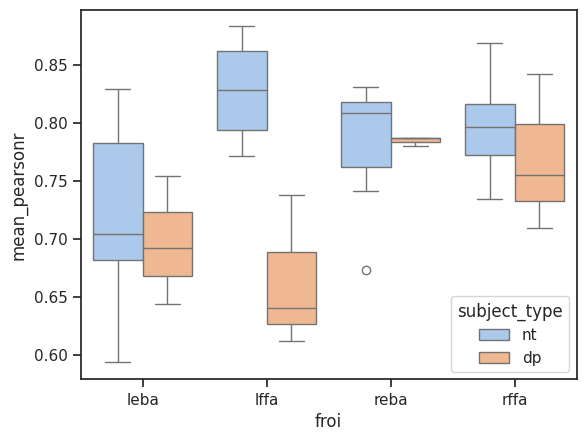

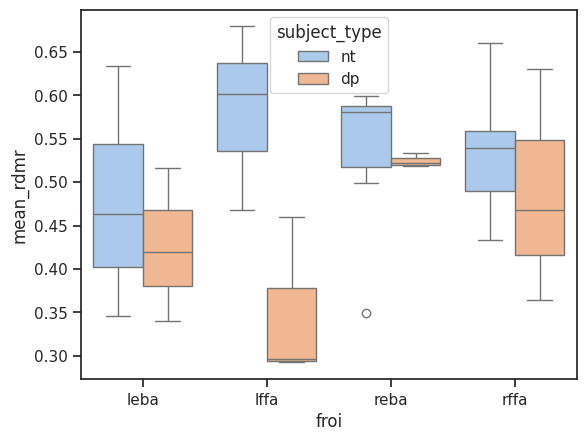

In [ ]:
sns.set_theme(style="ticks",palette="pastel")
used_metrics = ['mean_pearsonr','mean_rdmr']
df = results_csv

for my_metric in used_metrics:
    plt.figure()

    best_metric = df.loc[
        df.groupby(["subject_type","froi","test_subject"])[my_metric].idxmax(),
        ["froi","subject_type","test_subject", "layer", my_metric]
    ]

    sns.boxplot(x=best_metric["froi"],
                y=best_metric[my_metric],
                hue=best_metric["subject_type"],
                hue_order=["nt", "dp"]
                )


## Early/Late Layers plot:

N-fold cross-validation
Within-subject training/testing

Across all layers (layers sweep)

- We want to eventually replicate the comparison between early/late layers
- We need this for each of the ROIs (lffa,leba,rffa,reba)


Note to self: change colors to gray for NT, red for DP later


## Stimuli:

Preferred/non-preferred stimuli scatterplot (maybe just do faces and not faces in ffa, for example?)

## test....

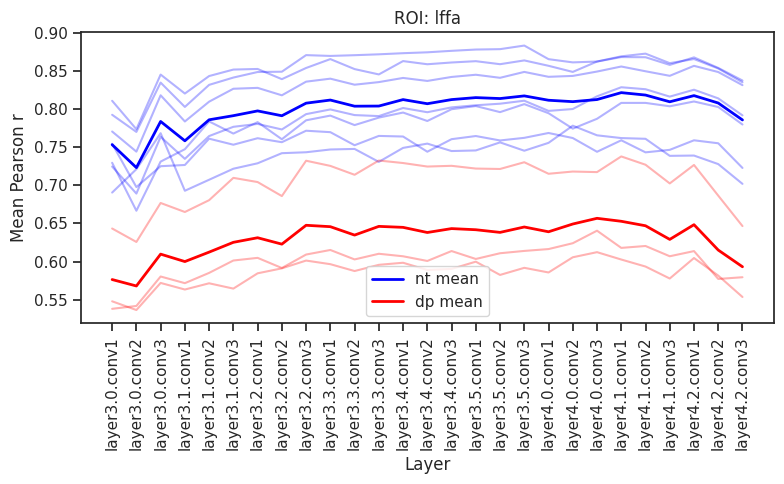

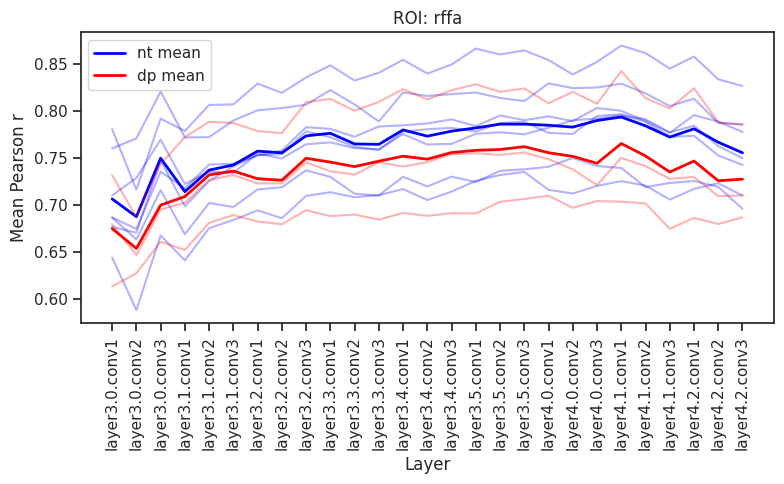

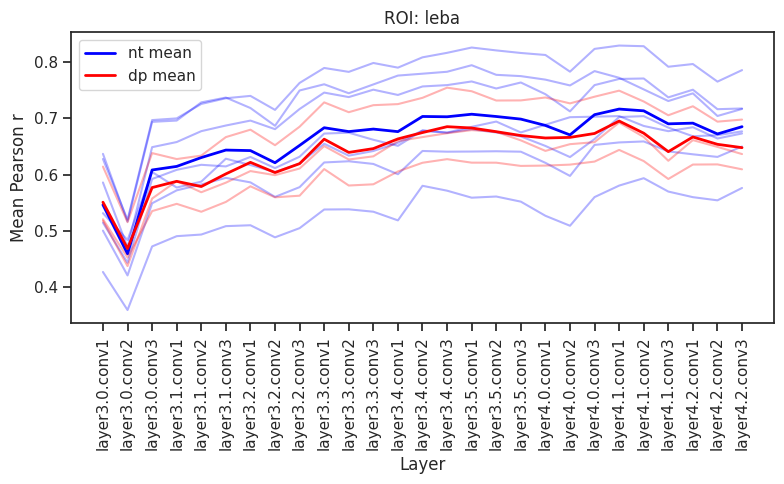

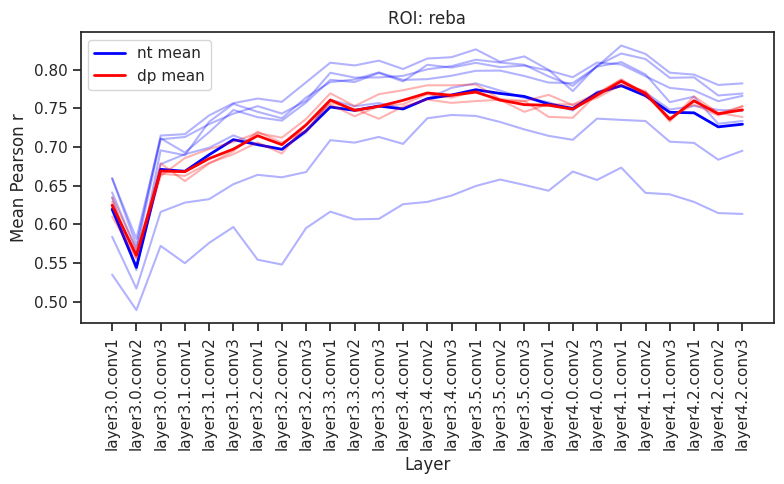

In [20]:
colors = {
    'nt': 'blue',
    'dp': 'red'
}

for froi in frois_considered:
    plt.figure(figsize=(8, 5))
    df_roi = df_results[df_results['froi'] == froi]
    
    for subtype in subtypes:
        df_group = df_roi[df_roi['subject_type'] == subtype]
        
        # individual subject lines
        for subj in df_group['test_subject'].unique():
            df_subj = df_group[df_group['test_subject'] == subj]
            df_subj = df_subj.sort_values('layer')
            
            plt.plot(
                df_subj['layer'],
                df_subj['mean_pearsonr'],
                color=colors[subtype],
                alpha=0.3
            )
        
        # group mean line (thicker)
        df_mean = (
            df_group
            .groupby('layer')['mean_pearsonr']
            .mean()
            .reset_index()
            .sort_values('layer')
        )
        
        plt.plot(
            df_mean['layer'],
            df_mean['mean_pearsonr'],
            color=colors[subtype],
            linewidth=2,   # <-- thicker line
            label=f'{subtype} mean'
        )
    
    plt.title(f'ROI: {froi}')
    plt.xlabel('Layer')
    plt.ylabel('Mean Pearson r')
    plt.xticks(rotation=90)
    plt.legend()
    plt.tight_layout()
    plt.show()